# 01. Exploratory Data Analysis (EDA) — NASA IMS Bearings

**Objetivo deste notebook:**
1. Inspecionar o dataset experimental da NASA IMS (**Set 2: `2nd_test`**).
2. Definir e implementar as formulações matemáticas das **features inferidas** (tempo e frequência).
3. Analisar a evolução temporal das vibrações e frequências características de defeito (**BPFO ~ 236.4 Hz**).
4. Mapear e justificar os cortes temporais para o protocolo de modelagem em `configs/labeling.yaml`:
   - **Zona de Treino (Healthy)**: `[0, train_end_idx]`
   - **Zona Cinza (Buffer/Transição)**: `[grey_start_idx, grey_end_idx]`
   - **Zona de Validação (Calibração de Limiar)**: `[val_start_idx, val_end_idx]`
   - **Zona de Teste (Degradação & Falha Anômala)**: `[test_start_idx, 981]`
   - **Parada Experimental (Motor Desligado)**: `[982, 983]`


In [ ]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuração de caminhos do projeto

_current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (_current, *_current.parents) if (path / "src").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the project root containing the `src` directory.")

# Put the project root first so `src` imports resolve correctly.
sys.path.insert(0, str(PROJECT_ROOT))


from src.data.loader import (
    list_ims_files,
    load_snapshot,
    load_timeline_metadata,
    detect_gaps,
    parse_timestamp,
)
from src.data.features import (
    compute_time_features,
    compute_fft_features,
    extract_features_df,
    DEFAULT_FFT_BANDS,
)
from src.utils.visualization import (
    set_plot_style,
    plot_dataset_timeline_zones,
    plot_raw_signal_comparison,
    plot_fft_spectrum_comparison,
)

set_plot_style()
print(f"Project root: {PROJECT_ROOT}")


Project root: C:\vscode\github\autoencoder_nasa_ims


## 1. Verificação do Dataset e Detecção de Lacunas (Gaps)

No setup do Set 2 (`2nd_test`):
- **4 Rolamentos Rexnord ZA-2115** montados em um mesmo eixo com carga radial de 6.000 lbs.
- Rotação: **2.000 RPM** (frequência fundamental do eixo $f_r \approx 33.33\text{ Hz}$).
- Taxa de amostragem canônica: **20.000 Hz** ($20.480$ pontos por arquivo $\approx 1.024\text{ s}$).
- Falha final: **Pista Externa (Outer Race) do Rolamento 1** (Canal 1).
- Rolamentos 2, 3 e 4 atuam como **controles negativos**.


In [3]:
interim_dir = PROJECT_ROOT / "data" / "interim" / "2nd_test"
files = list_ims_files(interim_dir)
print(f"Total de arquivos encontrados: {len(files)} (Esperado: 984)")

# Metadados de timestamp e detecção de lacunas
df_meta = load_timeline_metadata(interim_dir)
gaps = detect_gaps(files, nominal_interval_minutes=10.0, threshold_ratio=1.5)

print(f"Início da coleta: {df_meta.iloc[0]['timestamp']}")
print(f"Fim da coleta   : {df_meta.iloc[-1]['timestamp']}")
print(f"Duração total   : {df_meta.iloc[-1]['elapsed_hours']:.1f} horas ({df_meta.iloc[-1]['elapsed_hours']/24:.2f} dias)")
print(f"Lacunas (>15 min): {len(gaps)}")
if len(gaps) == 0:
    print("-> Coleta 100% contínua a cada 10 minutos nominais, sem interrupções.")
else:
    display(gaps)


Total de arquivos encontrados: 984 (Esperado: 984)
Início da coleta: 2004-02-12 10:32:39
Fim da coleta   : 2004-02-19 06:22:39
Duração total   : 163.8 horas (6.83 dias)
Lacunas (>15 min): 0
-> Coleta 100% contínua a cada 10 minutos nominais, sem interrupções.


## 2. Formulações Matemáticas das Features Inferidas

Cada snapshot de $N = 20.480$ pontos por canal é sintetizado em um vetor de features estatísticas e espectrais:

### A. Domínio do Tempo

1. **RMS (Root Mean Square)**:
   $$\text{RMS} = \sqrt{\frac{1}{N} \sum_{i=1}^N x_i^2}$$
   *Interpretação mecânica:* Mede a energia contínua e a amplitude global de vibração. Tende a subir nos estágios intermediários e finais da degradação.

2. **Pico Absoluto (Peak)**:
   $$\text{Peak} = \max_{i=1..N} |x_i|$$
   *Interpretação mecânica:* Amplitude máxima instantânea provocada pelo choque do corpo rolante sobre o defeito.

3. **Pico a Pico (Peak-to-Peak / P2P)**:
   $$\text{P2P} = \max(x) - \min(x)$$
   *Interpretação mecânica:* Variação dinâmica total do sinal na janela de 1 segundo.

4. **Fator de Crista (Crest Factor)**:
   $$\text{CF} = \frac{\text{Peak}}{\text{RMS}}$$
   *Interpretação mecânica:* Razão entre o pico e o valor eficaz médio. Muito sensível aos primeiros micropites, pois o pico sobe antes do RMS aumentar.

5. **Curtose (Pearson Kurtosis)**:
   $$\text{Kurtosis} = \frac{\frac{1}{N} \sum_{i=1}^N (x_i - \bar{x})^4}{\left( \frac{1}{N} \sum_{i=1}^N (x_i - \bar{x})^2 \right)^2}$$
   *Interpretação mecânica:* Grau de achatamento da distribuição. Sinais gaussianos saudáveis têm $\text{Kurtosis} \approx 3.0$. O surgimento de impactos periódicos gera caudas pesadas, elevando a curtose para valores $> 4.5$.

---

### B. Domínio da Frequência (FFT)

- Frequência de amostragem: $f_s = 20.000\text{ Hz}$, $N = 20.480$ pontos.
- Resolução espectral: $\Delta f = \frac{f_s}{N} = \frac{20000}{20480} \approx 0.9765625\text{ Hz}$.
- Espectro unilateral de magnitude: $|X(f_k)| = |\text{rfft}(x)|$.

**Energia por Banda de Frequência:**
$$E_{\text{band}} = \sum_{f_k \in [f_{\min}, f_{\max}]} |X(f_k)|^2$$

Bandas configuradas conforme `configs/data.yaml`:
- **`low`** $[0, 500]\text{ Hz}$: Vibrações mecânicas de baixa ordem e desbalanceamento rotativo ($1\times, 2\times, 3\times$ RPM).
- **`mid`** $[500, 2000]\text{ Hz}$: Faixa intermediária de harmônicos e excitação dinâmica.
- **`high`** $[2000, 5000]\text{ Hz}$: Frequências estruturais e ruído de banda larga gerado por atrito e micro-desgaste.
- **`bpfo`** $[216, 256]\text{ Hz}$: Frequência teórica de passagem das esferas na pista externa (BPFO $\approx 236.4\text{ Hz} \pm 8.5\%$).
- **`bpfi`** $[272, 322]\text{ Hz}$: Frequência teórica da pista interna (BPFI $\approx 296.9\text{ Hz} \pm 8.5\%$).
- **`bsf2x`** $[255, 302]\text{ Hz}$: Duplo da frequência de rotação da esfera ($2\times\text{BSF} \approx 278.4\text{ Hz} \pm 8.5\%$).


In [4]:
# Extração de features com cache em disco para agilidade
features_cache = PROJECT_ROOT / "data" / "processed" / "2nd_test_features.csv"

df_features = extract_features_df(
    files=files,
    fs=20000.0,
    channel_names=["b1", "b2", "b3", "b4"],
    bands=DEFAULT_FFT_BANDS,
    cache_path=features_cache,
    show_progress=True,
)

print(f"Features extraídas com sucesso! Dimensões: {df_features.shape}")
df_features[["idx", "b1_rms", "b1_kurtosis", "b1_crest_factor", "b1_energy_bpfo", "b2_rms"]].head()


Extracting features: 100%|██████████| 984/984 [00:19<00:00, 50.46it/s]

Features extraídas com sucesso! Dimensões: (984, 47)


,idx,b1_rms,b1_kurtosis,b1_crest_factor,b1_energy_bpfo,b2_rms
0,0,0.074179,3.628763,6.120331,6815.750012,0.090944
1,1,0.075382,3.648291,5.147086,10274.379255,0.093419
2,2,0.076230,3.513475,6.598472,5743.759894,0.093718
3,3,0.078724,4.157953,7.723217,5326.752735,0.092947
4,4,0.078474,3.603177,4.982524,4263.882836,0.095348


## 3. Comparação de Formas de Onda no Tempo e Espectros FFT

Visualização física dos sinais em três instantes da vida útil:
1. **Saudável (Índice 100)**: Vibração gaussiana de baixa amplitude.
2. **Degradação Inicial (Índice 600)**: Impactos repetitivos de amplitude moderada.
3. **Falha Severa (Índice 975)**: Destruição da pista externa com impactos violentos.


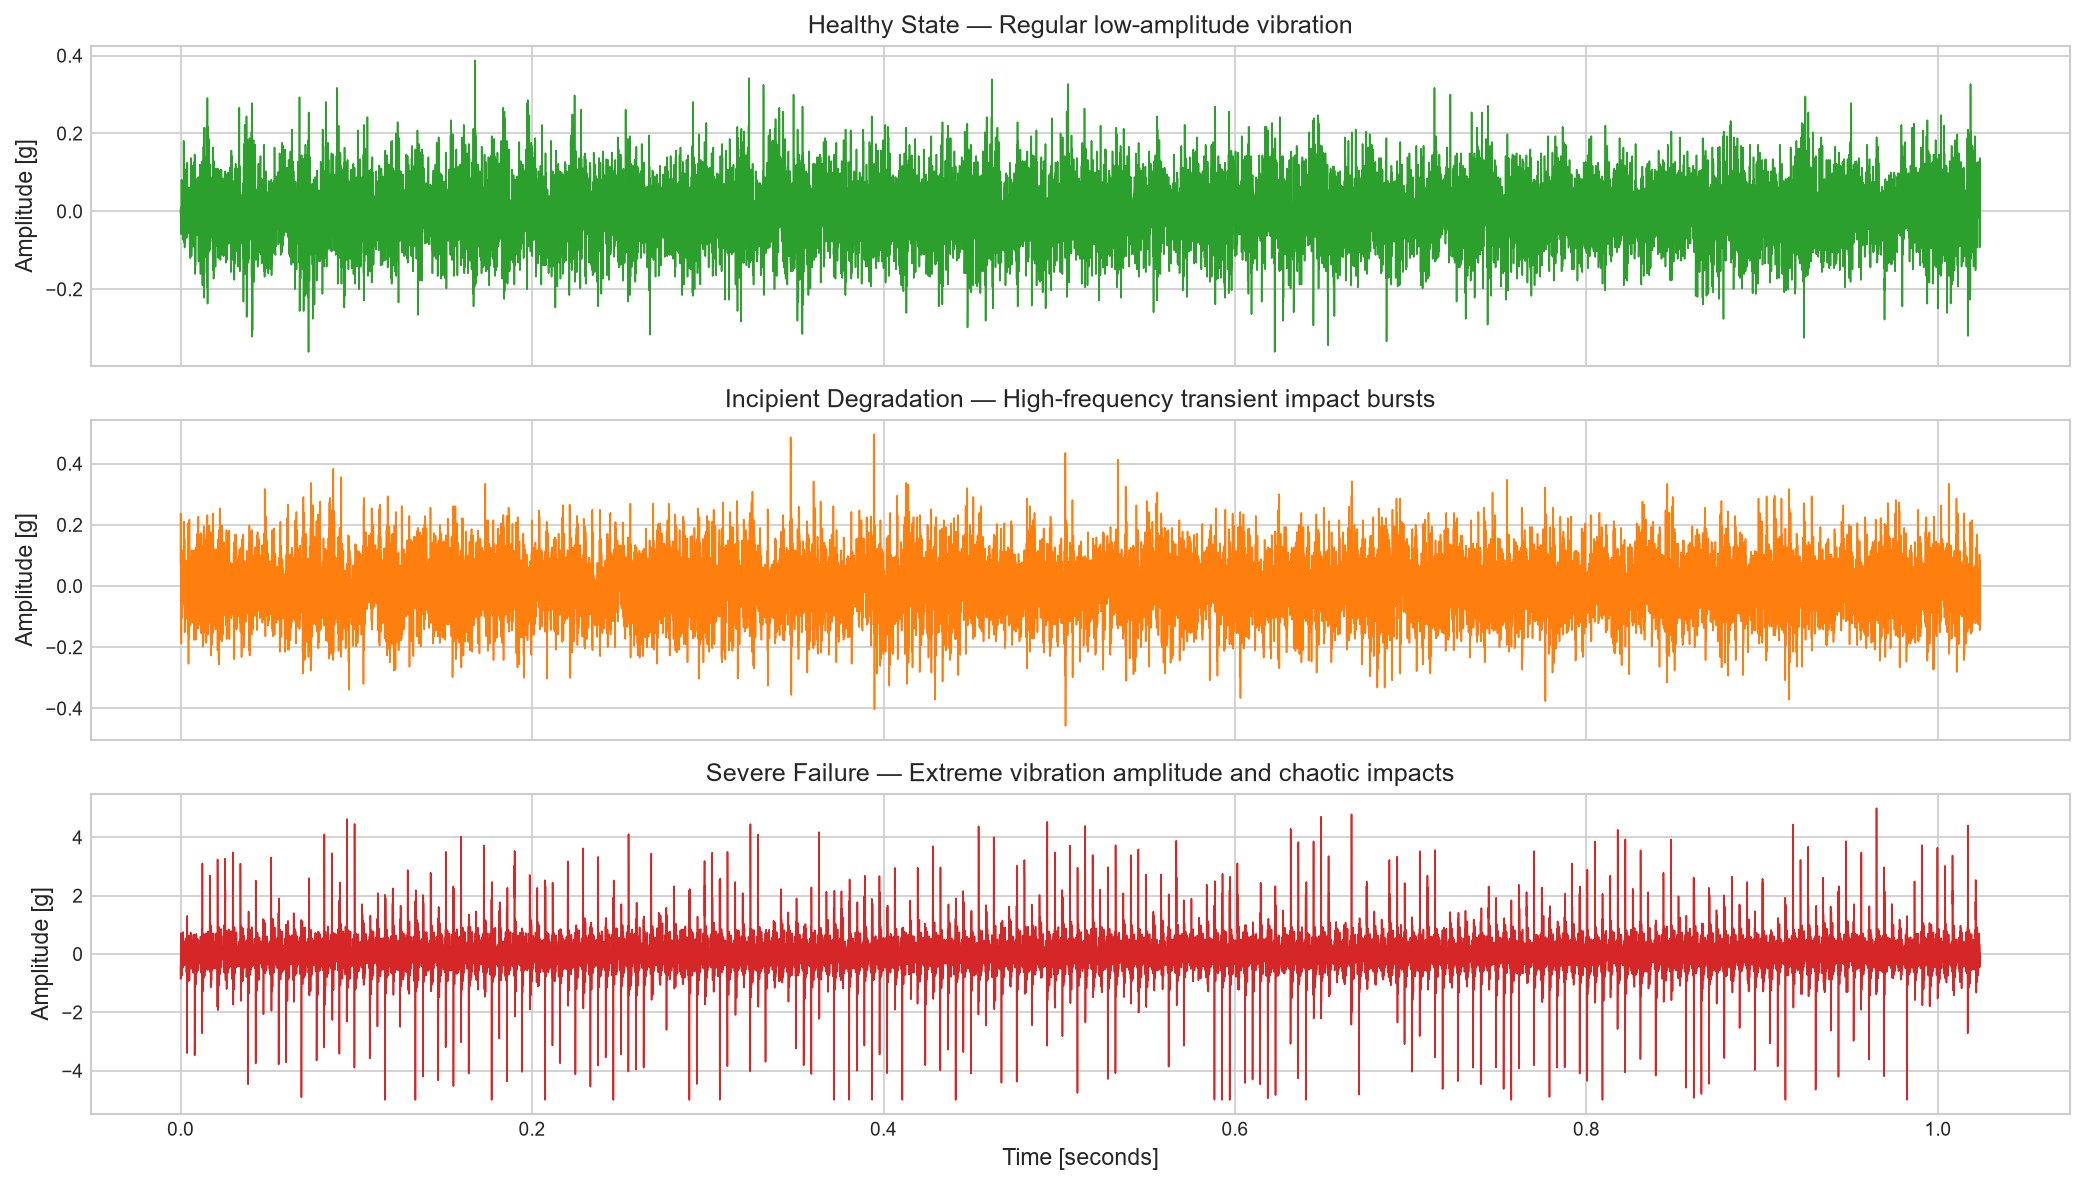

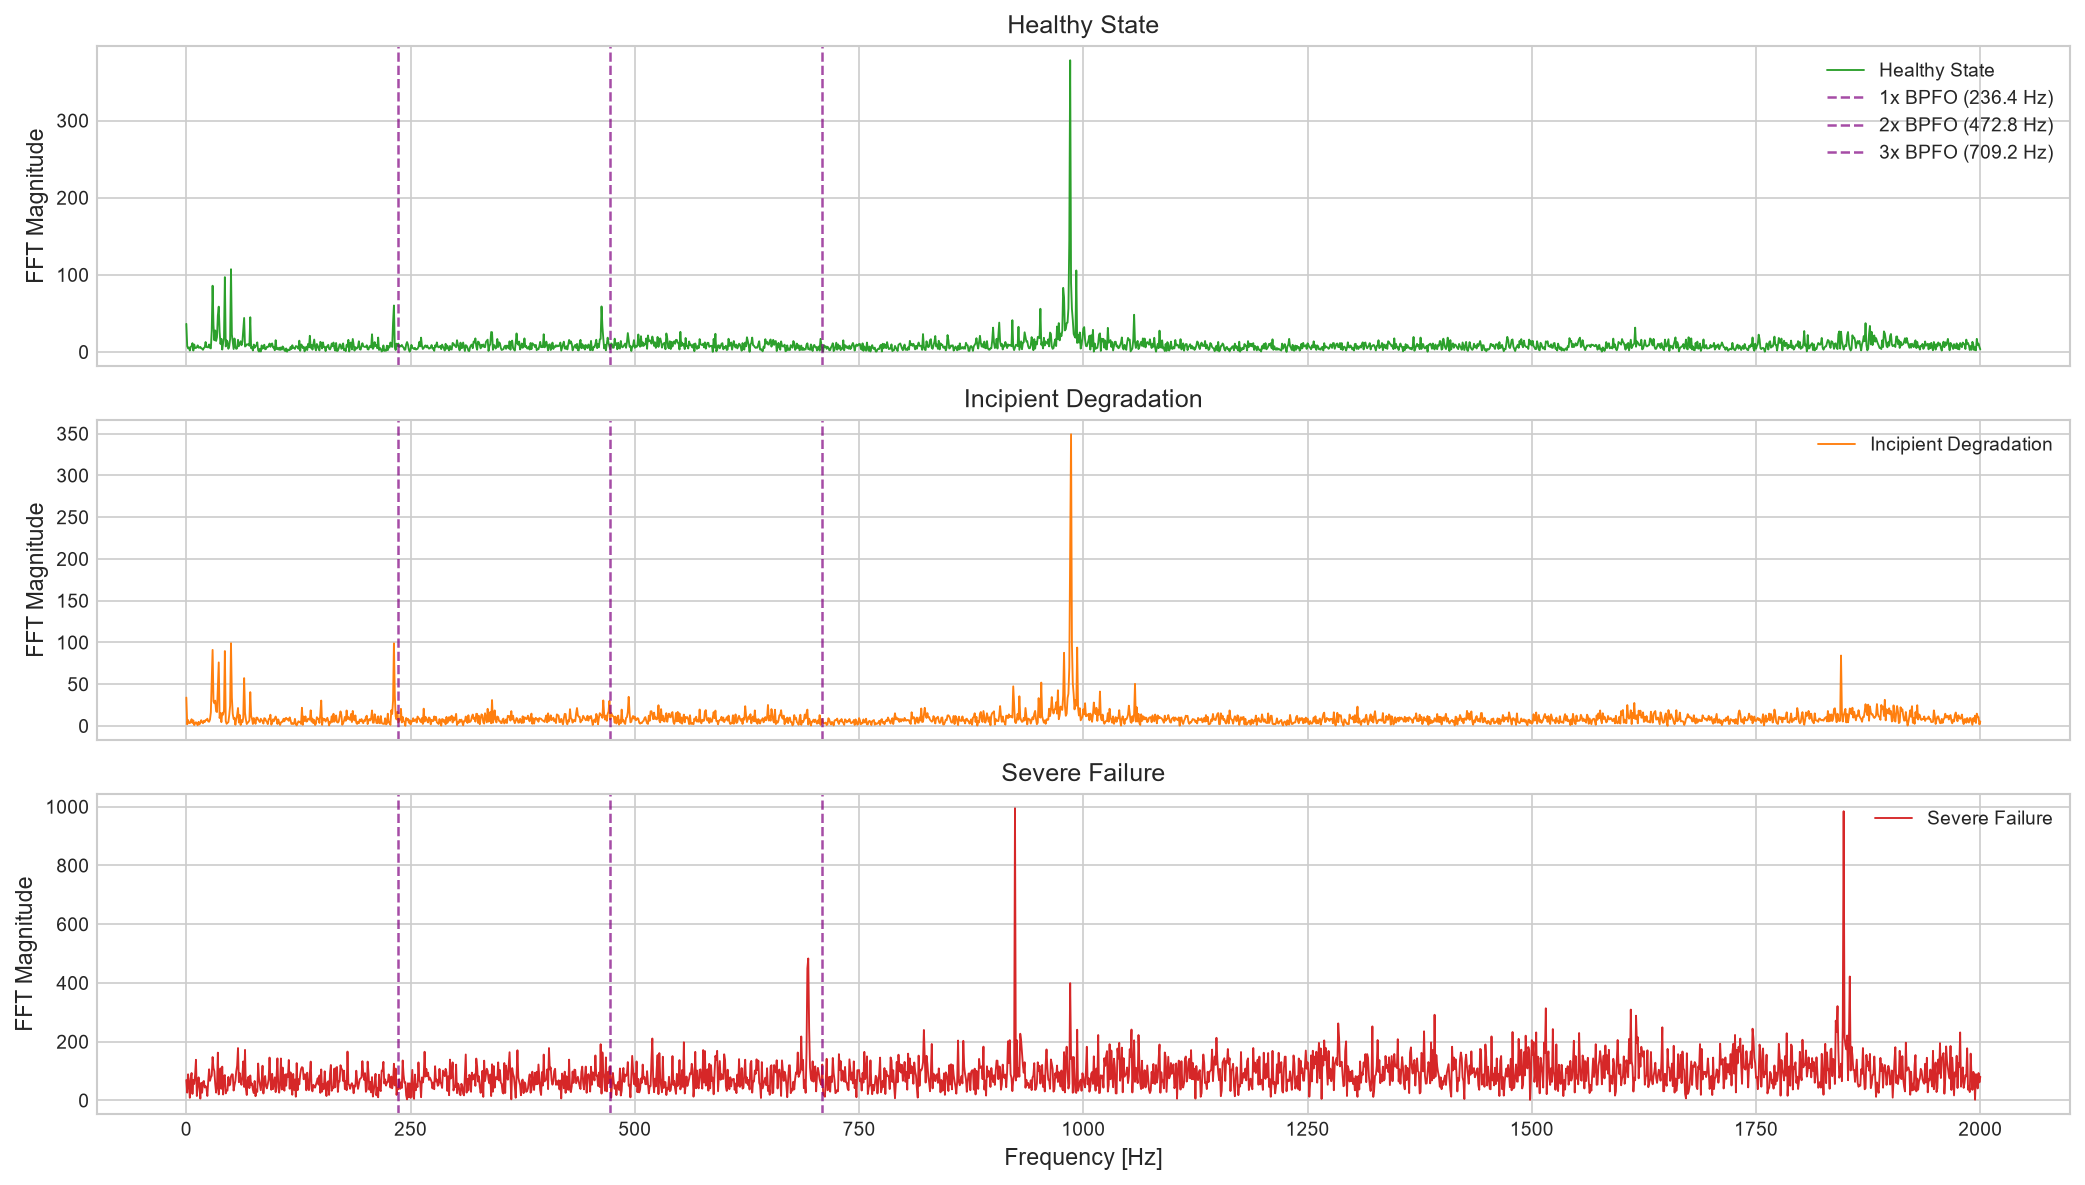

In [5]:
h_sig = load_snapshot(files[100])[:, 0]
d_sig = load_snapshot(files[600])[:, 0]
f_sig = load_snapshot(files[975])[:, 0]

fig_wave = plot_raw_signal_comparison(
    h_sig,
    d_sig,
    f_sig,
    output_path=PROJECT_ROOT / "reports" / "eda_waveform_comparison.png",
)
plt.show()

fig_fft = plot_fft_spectrum_comparison(
    h_sig,
    d_sig,
    f_sig,
    bpfo=236.4,
    output_path=PROJECT_ROOT / "reports" / "eda_fft_spectrum.png",
)
plt.show()

## 4. Análise Temporal e Proposta de Zonas de Corte (`labeling.yaml`)

### Justificativa dos Cortes:

1. **Zona de Treino (`train_end_idx = 400`)**:
   - Do índice `0` ao `400` (primeiras 66 horas), todos os rolamentos operam em regime saudável estritamente estacionário ($	ext{RMS} \approx 0.077\text{ g}$, $\text{Kurtosis} \approx 3.5$).
   - O autoencoder aprende exclusivamente a representação do estado saudável não-degradado.

2. **Zona Cinza (`grey_start_idx = 401`, `grey_end_idx = 450`)**:
   - Intervalo de resguardo (buffer) de 50 snapshots (~8.3 horas).
   - Excluído completamente de treino, validação e teste para evitar contaminação ou descontinuidades de borda.

3. **Zona de Validação (`val_start_idx = 451`, `val_end_idx = 530`)**:
   - Período saudável imediatamente anterior ao surgimento do defeito.
   - Utilizado **estritamente para calibrar o limiar de anomalia** (ex: percentil 99 do erro de reconstrução), garantindo zero falsos alarmes no regime normal.

4. **Zona de Teste / Degradação / Falha (`test_start_idx = 531` até `981`)**:
   - A literatura (Hai Qiu et al., 2006) e a análise espectral confirmam que o defeito de pista externa surge por volta do índice 532.
   - A degradação acelera a partir do índice 700 e atinge o colapso estrutural no índice 981.

5. **Parada Experimental (`shutdown_idx = 982` e `983`)**:
   - No índice 982 o motor foi desligado ($	ext{RMS} < 0.002\text{ g}$). Essa região é ruído de equipamento desenergizado e não entra na avaliação.


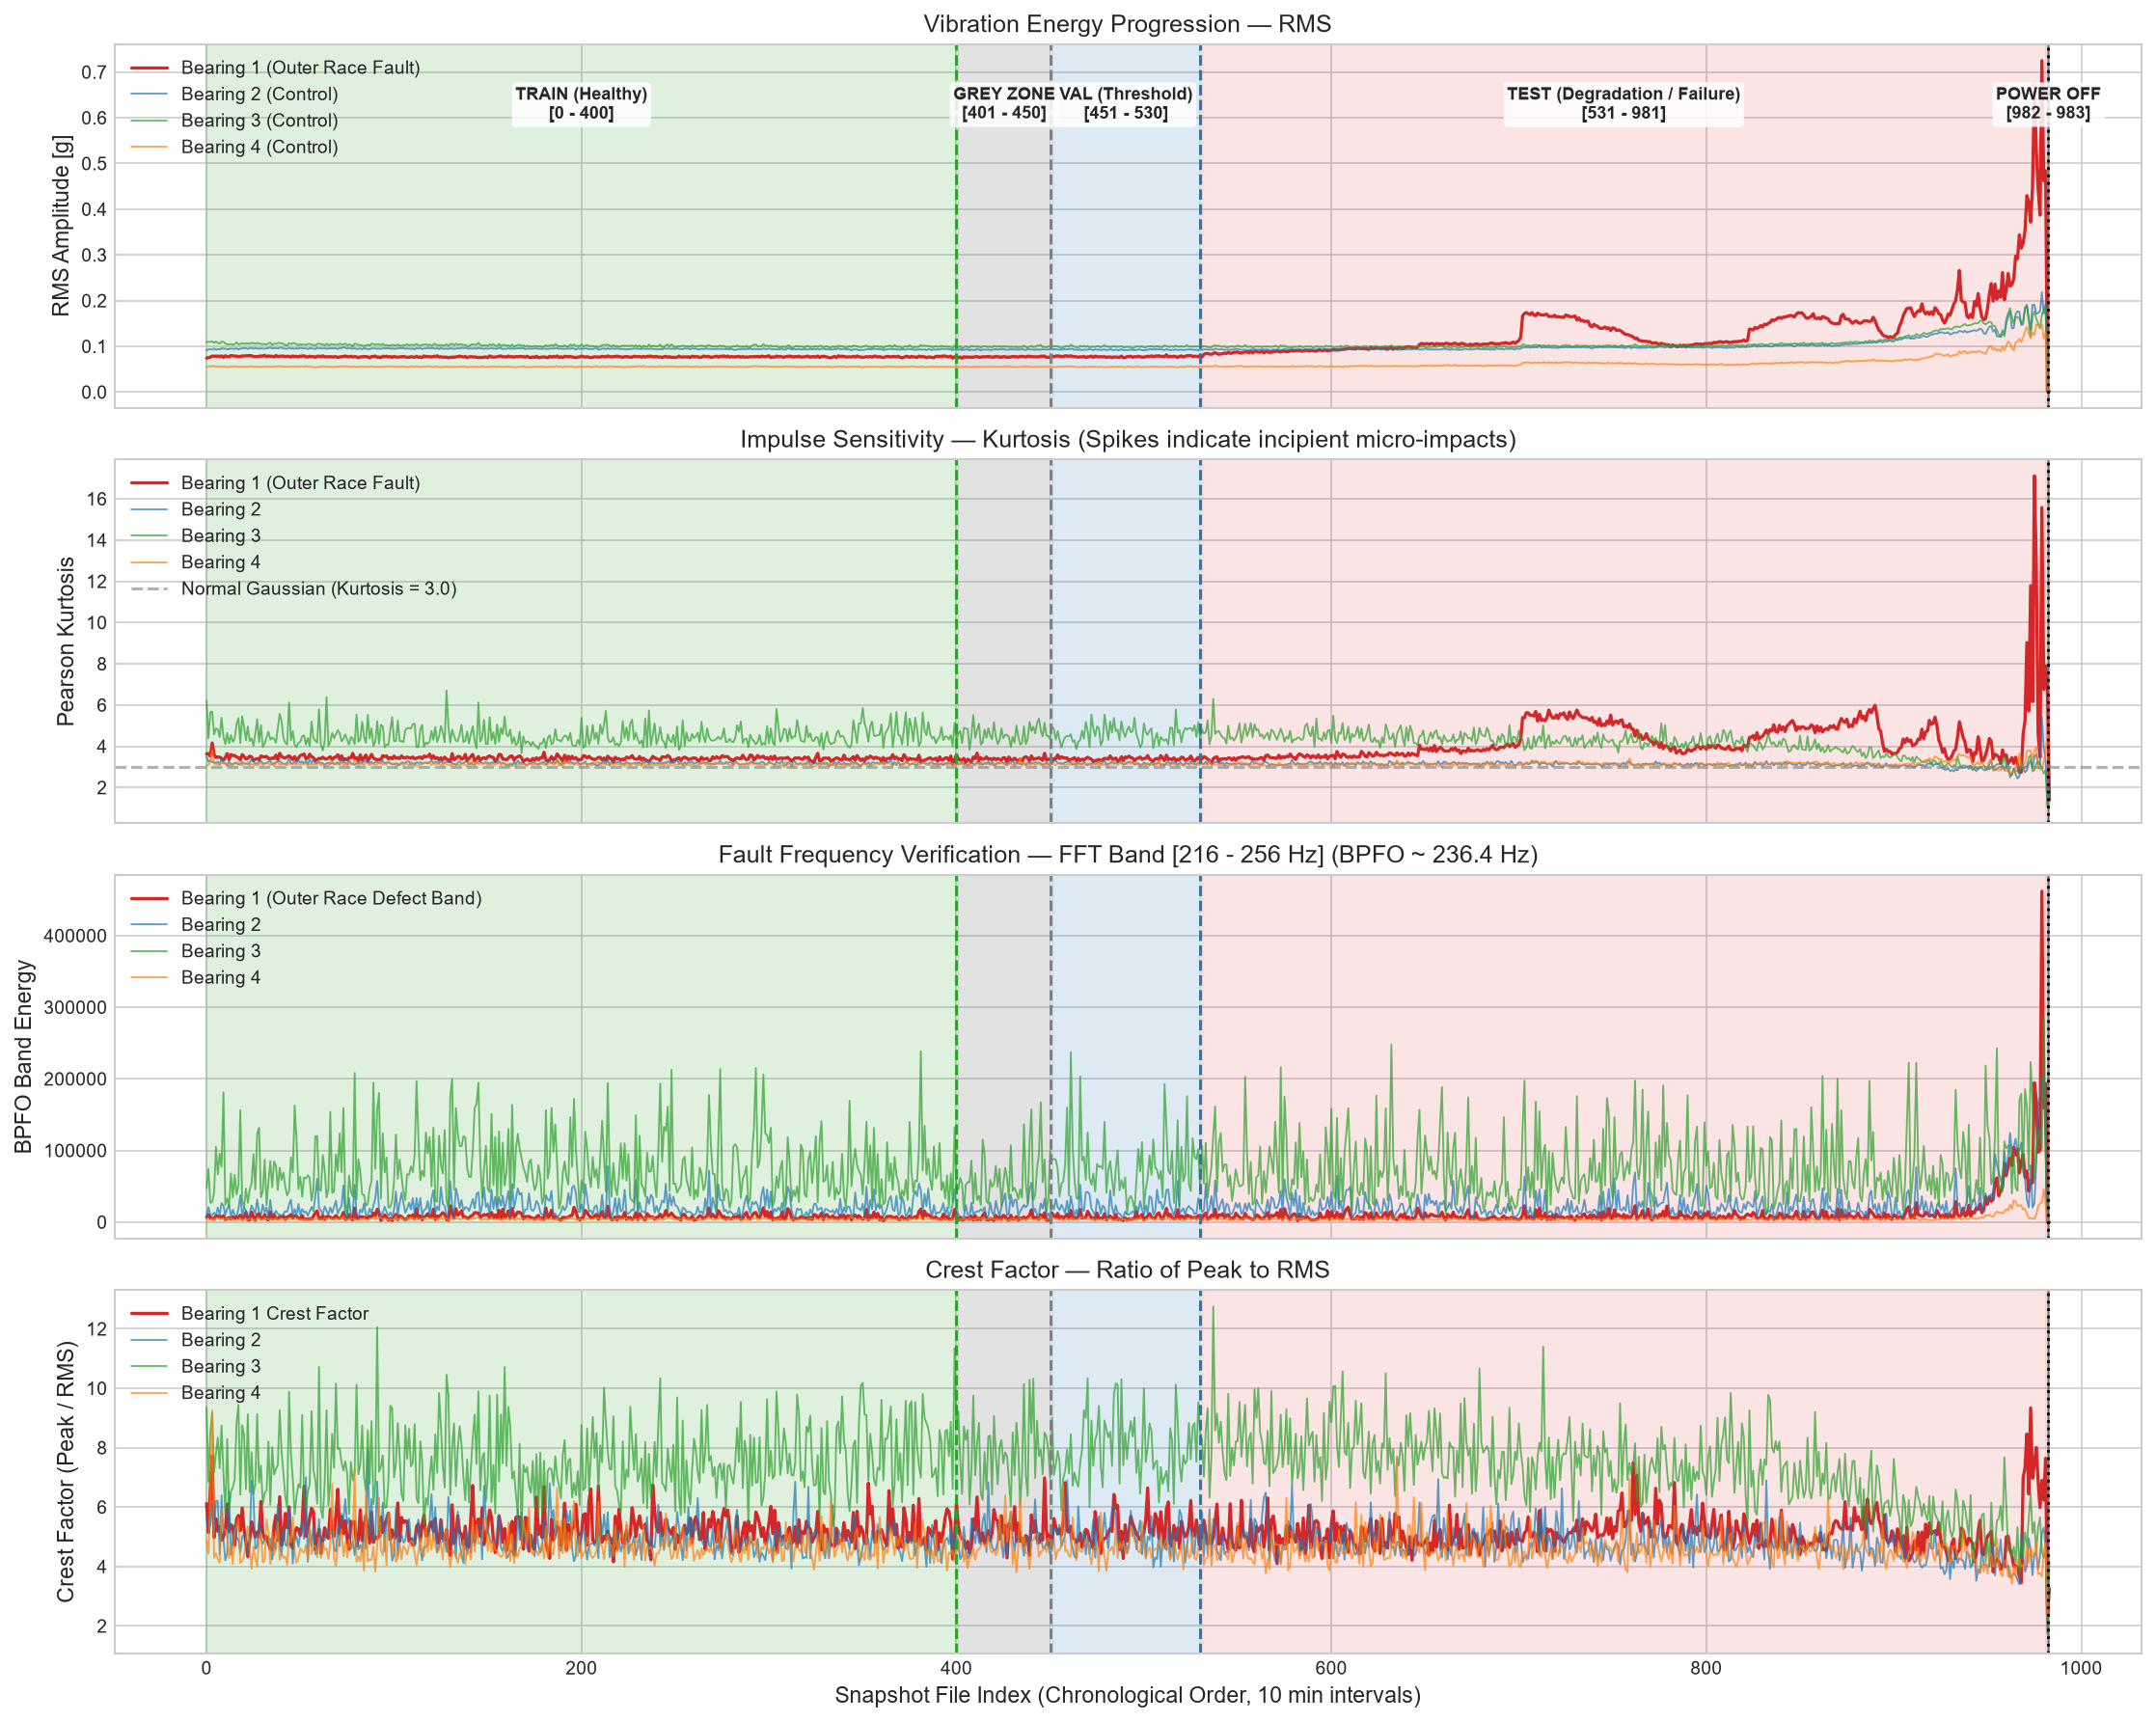

In [6]:
fig_zones = plot_dataset_timeline_zones(
    df_features=df_features,
    train_end_idx=400,
    grey_start_idx=401,
    grey_end_idx=450,
    val_start_idx=451,
    val_end_idx=530,
    test_start_idx=531,
    shutdown_idx=982,
    output_path=PROJECT_ROOT / "reports" / "eda_zones_timeline.png",
)
plt.show()

## 5. Parâmetros Propostos para `configs/labeling.yaml`

Após aprovação dos cortes, a seção `2nd_test` em `configs/labeling.yaml` será preenchida:

```yaml
sets:
  "2nd_test":
    train_end_idx: 400        # Último arquivo saudável do treino (0 a 400 = 401 arquivos)
    grey_start_idx: 401       # Início da zona cinza excluída
    grey_end_idx: 450         # Fim da zona cinza excluída (50 arquivos)
    val_start_idx: 451        # Início da validação para calibração de limiar
    val_end_idx: 530          # Fim da validação (80 arquivos)
    test_start_idx: 531       # Início do teste: início da degradação outer race até a falha
    shutdown_idx: 982         # Motor desligado
    note: "Definido e validado via 01_EDA.ipynb. Defeito outer race surge no arquivo 532."
    approved_by: "EDA / Team"
    frozen: false
```
